# 1. Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical tests
from statsmodels.tsa.stattools import adfuller, kpss
from arch.unitroot import PhillipsPerron

# Variance ratio
from arch.unitroot import VarianceRatio

# Autocorrelation
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# ARIMA
from statsmodels.tsa.arima.model import ARIMA

# Runs test
from statsmodels.sandbox.stats.runs import runstest_1samp

# GARCH
from arch import arch_model

import matplotlib.pyplot as plt
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.preprocessing import MinMaxScaler

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split



import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping



from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [2]:
df = pd.read_csv("Levels.csv")

C:\Users\vkpoa\AppData\Local\Temp\ipykernel_19512\2614113232.py:1: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("Levels.csv")


In [3]:
print(df.columns)

Index(['Date', 'Index'], dtype='object')


In [4]:

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1032473 entries, 0 to 1032472
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Date    281 non-null    object
 1   Index   18488 non-null  object
dtypes: object(2)
memory usage: 15.8+ MB


In [5]:
# Remove rows where Date or Index is missing
df = df.dropna(subset=["Date", "Index"])

# Convert the Index column to numeric
df["Index"] = pd.to_numeric(df["Index"], errors="coerce")

# Remove any remaining missing values

df = df.dropna(subset=["Index"])

# Convert dates
df["Date"] = pd.to_datetime(df["Date"], format="%b-%y")

# Sort by date
df = df.sort_values("Date").reset_index(drop=True)

df.info()
df.head()
df.tail()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 281 entries, 0 to 280
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    281 non-null    datetime64[ns]
 1   Index   281 non-null    float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 4.5 KB


,Date,Index
276,2025-12-01,8770.25
277,2026-01-01,9006.51
278,2026-02-01,12869.20
279,2026-03-01,13060.13
280,2026-04-01,15130.50


In [6]:
df.shape

(281, 2)

In [7]:


df.describe().round(2)

,Date,Index
count,281,281.00
mean,2014-08-01 05:53:35.658362880,3880.61
min,2002-12-01 00:00:00,969.03
25%,2008-10-01 00:00:00,2084.72
50%,2014-08-01 00:00:00,2741.46
75%,2020-06-01 00:00:00,5378.72
max,2026-04-01 00:00:00,15130.50
std,NaN,2588.06


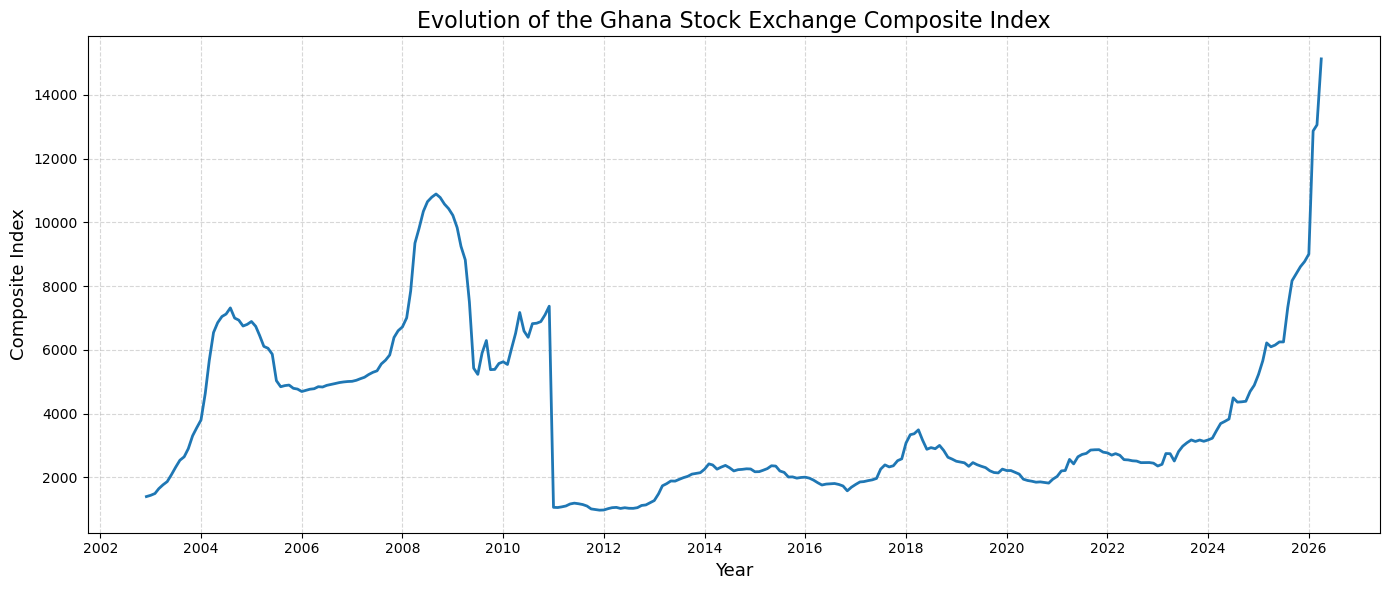

In [8]:

import matplotlib.dates as mdates

# Sort by date
df = df.sort_values('Date')

plt.figure(figsize=(14,6))

plt.plot(
    df['Date'],
    df['Index'],
    linewidth=2
)

plt.title('Evolution of the Ghana Stock Exchange Composite Index', fontsize=16)
plt.xlabel('Year', fontsize=13)
plt.ylabel('Composite Index', fontsize=13)

# Display one tick every two years
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.xticks(rotation=0)

plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()

plt.savefig('gse_composite_index.png', dpi=300, bbox_inches='tight')

plt.show()

# 5. Compute Log Returns

In [9]:
df['Returns'] = np.log(df['Index']).diff()



In [10]:
print(df.columns)

Index(['Date', 'Index', 'Returns'], dtype='object')


In [11]:
df.head()

,Date,Index,Returns
0,2002-12-01,1395.31,NaN
1,2003-01-01,1434.71,0.027846
2,2003-02-01,1491.03,0.038504
3,2003-03-01,1643.71,0.097489
4,2003-04-01,1766.44,0.072010


In [12]:
df['Returns'] = np.log(df['Index'] / df['Index'].shift(1))

In [13]:
df.head()

,Date,Index,Returns
0,2002-12-01,1395.31,NaN
1,2003-01-01,1434.71,0.027846
2,2003-02-01,1491.03,0.038504
3,2003-03-01,1643.71,0.097489
4,2003-04-01,1766.44,0.072010


In [14]:
#Remove first NaN observation

df = df.dropna(subset=['Returns'])

In [15]:
df.head()

,Date,Index,Returns
1,2003-01-01,1434.71,0.027846
2,2003-02-01,1491.03,0.038504
3,2003-03-01,1643.71,0.097489
4,2003-04-01,1766.44,0.072010
5,2003-05-01,1864.95,0.054268


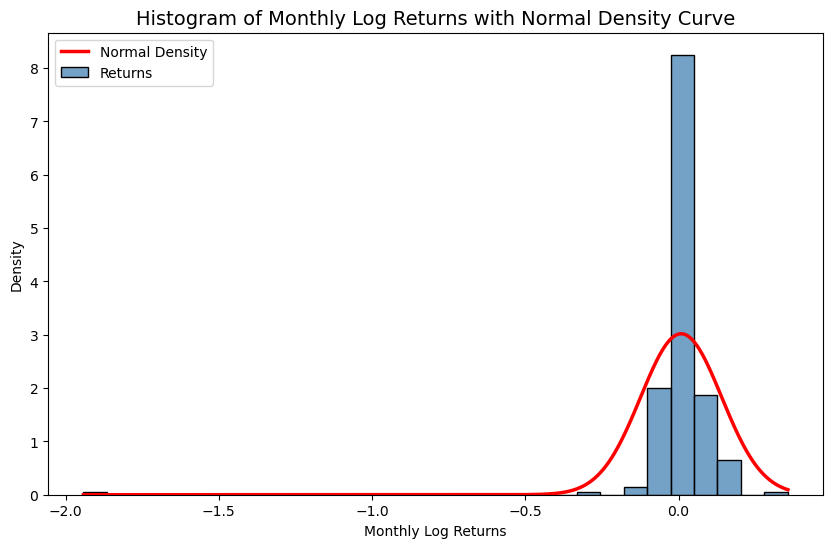

In [16]:

from scipy.stats import norm

mu = df['Returns'].mean()
sigma = df['Returns'].std()

plt.figure(figsize=(10,6))

sns.histplot(
    df['Returns'],
    bins=30,
    stat='density',
    kde=False,
    color='steelblue',
    edgecolor='black',
    label='Returns'
)

x = np.linspace(df['Returns'].min(), df['Returns'].max(), 1000)
plt.plot(x, norm.pdf(x, mu, sigma),
         color='red',
         linewidth=2.5,
         label='Normal Density')

plt.title('Histogram of Monthly Log Returns with Normal Density Curve', fontsize=14)
plt.xlabel('Monthly Log Returns')
plt.ylabel('Density')
plt.legend()

plt.show()

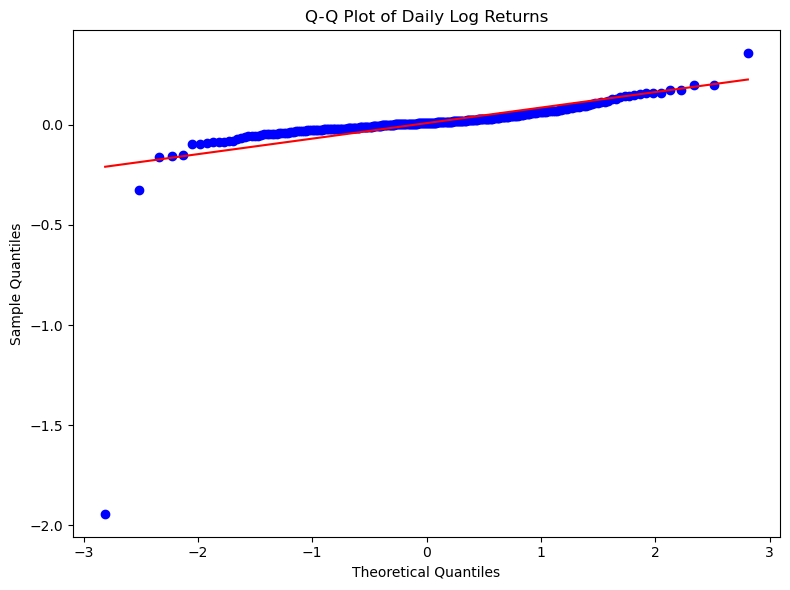

In [17]:
import matplotlib.pyplot as plt
from scipy import stats

# Q-Q Plot of Returns
plt.figure(figsize=(8,6))

stats.probplot(df['Returns'], dist="norm", plot=plt)

plt.title("Q-Q Plot of Daily Log Returns")
plt.xlabel("Theoretical Quantiles")
plt.ylabel("Sample Quantiles")

plt.tight_layout()
plt.show()

In [18]:
df.head(50)

,Date,Index,Returns
1,2003-01-01,1434.71,0.027846
2,2003-02-01,1491.03,0.038504
3,2003-03-01,1643.71,0.097489
4,2003-04-01,1766.44,0.072010
5,2003-05-01,1864.95,0.054268
6,2003-06-01,2084.72,0.111400
7,2003-07-01,2315.26,0.104887
8,2003-08-01,2535.56,0.090893
9,2003-09-01,2643.34,0.041629
10,2003-10-01,2899.03,0.092333


In [19]:
df.describe().T.round(3)

,count,mean,min,25%,50%,75%,max,std
Date,280,2014-08-16 11:08:34.285714176,2003-01-01 00:00:00,2008-10-24 06:00:00,2014-08-16 12:00:00,2020-06-08 12:00:00,2026-04-01 00:00:00,NaN
Index,280.0,3889.482289,969.03,2096.09,2742.155,5380.66,15130.5,2588.403108
Returns,280.0,0.008513,-1.941742,-0.01676,0.008906,0.038147,0.356889,0.132196


In [20]:
desc = pd.DataFrame({
    'Count': [df['Returns'].count()],
    'Mean': [df['Returns'].mean()],
    'Std. Dev.': [df['Returns'].std()],
    'Skewness': [df['Returns'].skew()],
    'Kurtosis': [df['Returns'].kurt()],
    'Minimum': [df['Returns'].min()],
    '25%': [df['Returns'].quantile(0.25)],
    'Median': [df['Returns'].median()],
    '75%': [df['Returns'].quantile(0.75)],
    'Maximum': [df['Returns'].max()]
})

print(desc.round(4))

   Count    Mean  Std. Dev.  Skewness  Kurtosis  Minimum     25%  Median  \
0    280  0.0085     0.1322  -11.5185  170.9164  -1.9417 -0.0168  0.0089   

      75%  Maximum  
0  0.0381   0.3569  


In [21]:
print(df['Returns'].kurt())                      # Excess kurtosis (Pandas)
from scipy.stats import kurtosis
print(kurtosis(df['Returns'], fisher=True))      # Excess kurtosis
print(kurtosis(df['Returns'], fisher=False))     # Pearson kurtosis

170.91644814630482
167.85823806367867
170.85823806367867


# 6. Plot Returns

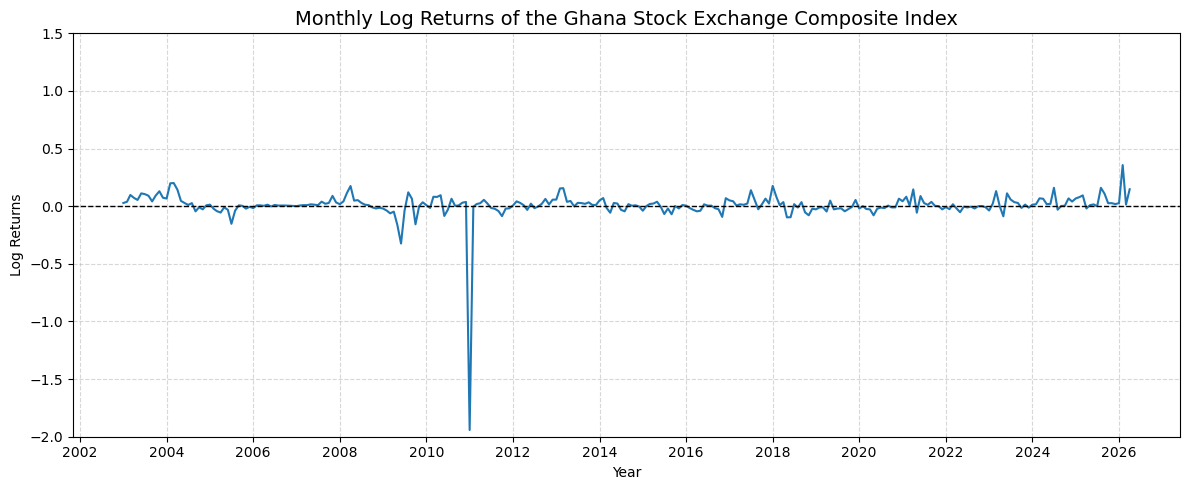

In [22]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

df = df.sort_values('Date')

fig, ax = plt.subplots(figsize=(12,5))

ax.plot(df['Date'], df['Returns'], linewidth=1.5)

# Horizontal line at zero
ax.axhline(y=0, color='black', linestyle='--', linewidth=1)
ax.set_ylim(-2, 1.5)

ax.set_title('Monthly Log Returns of the Ghana Stock Exchange Composite Index', fontsize=14)
ax.set_xlabel('Year')
ax.set_ylabel('Log Returns')

ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.xticks(rotation=0)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# 7.Unit Root and Stationarity Tests

### Augmented  Dickey Fuller

In [23]:
adf_test = adfuller(df['Returns'])

print("ADF Statistic:", adf_test[0])
print("p-value:", adf_test[1])

print("\nCritical Values:")
for key, value in adf_test[4].items():
    print(f"   {key}: {value:.3f}")

# Decision
if adf_test[1] < 0.05:
    print("\nConclusion: The log return series is stationary.")
else:
    print("\nConclusion: The log return series is non-stationary.")

ADF Statistic: -15.287339936438515
p-value: 4.492119021353013e-28

Critical Values:
   1%: -3.454
   5%: -2.872
   10%: -2.572

Conclusion: The log return series is stationary.


### Phillips-Perron

In [24]:
pp_test = PhillipsPerron(df['Returns'])

print(pp_test.summary())

     Phillips-Perron Test (Z-tau)    
Test Statistic                -15.651
P-value                         0.000
Lags                               16
-------------------------------------

Trend: Constant
Critical Values: -3.45 (1%), -2.87 (5%), -2.57 (10%)
Null Hypothesis: The process contains a unit root.
Alternative Hypothesis: The process is weakly stationary.


### KPSS

In [25]:
kpss_test = kpss(df['Returns'], regression='c')

print("KPSS Statistic:", kpss_test[0])
print("p-value:", kpss_test[1])
print("Critical Values:", kpss_test[3])

KPSS Statistic: 0.19426067348815929
p-value: 0.1
Critical Values: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}


C:\Users\vkpoa\AppData\Local\Temp\ipykernel_19512\1752083049.py:1: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_test = kpss(df['Returns'], regression='c')


# Random Walk Tests

### Variance Ratio Test

In [26]:
for lag in [2,5,10,15,20]:
    vr = VarianceRatio(df['Returns'], lags=lag)
    print(f"\nVariance Ratio Test (lag={lag})")
    print(vr.summary())


Variance Ratio Test (lag=2)
     Variance-Ratio Test Results     
Test Statistic                 -1.099
P-value                         0.272
Lags                                2
-------------------------------------

Computed with overlapping blocks (de-biased)

Variance Ratio Test (lag=5)
     Variance-Ratio Test Results     
Test Statistic                 -1.138
P-value                         0.255
Lags                                5
-------------------------------------

Computed with overlapping blocks (de-biased)

Variance Ratio Test (lag=10)
     Variance-Ratio Test Results     
Test Statistic                 -1.138
P-value                         0.255
Lags                               10
-------------------------------------

Computed with overlapping blocks (de-biased)

Variance Ratio Test (lag=15)
     Variance-Ratio Test Results     
Test Statistic                 -1.146
P-value                         0.252
Lags                               15
----------------------

In [27]:
vr_test = VarianceRatio(df['Returns'], lags=2)

print(vr_test.summary())

     Variance-Ratio Test Results     
Test Statistic                 -1.099
P-value                         0.272
Lags                                2
-------------------------------------

Computed with overlapping blocks (de-biased)


### Runs Test (Randomness)

In [28]:
from statsmodels.sandbox.stats.runs import runstest_1samp

z, p = runstest_1samp(df['Returns'])

print("Runs Test Z:", z)
print("p-value:", p)

Runs Test Z: -7.898626598381531
p-value: 2.819932716845614e-15


In [29]:
median = np.median(df['Returns'])

runs_test = runstest_1samp(df['Returns'], cutoff=median)

print("Z-statistic:", runs_test[0])
print("p-value:", runs_test[1])

Z-statistic: -7.423733502499646
p-value: 1.138641534473511e-13


# 9. Dependence Tests

### Autocorrelation

In [30]:
ljung_box = acorr_ljungbox(df['Returns'], lags=[2,5,10,20], return_df=True)
print(ljung_box)

      lb_stat  lb_pvalue
2    2.353128   0.308336
5    3.285719   0.656029
10   7.071104   0.718716
20  15.388837   0.753743


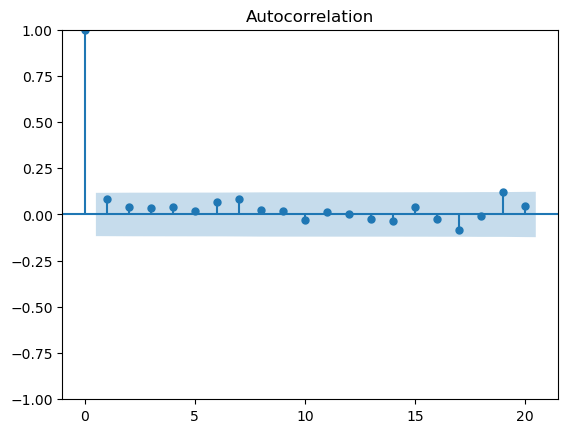

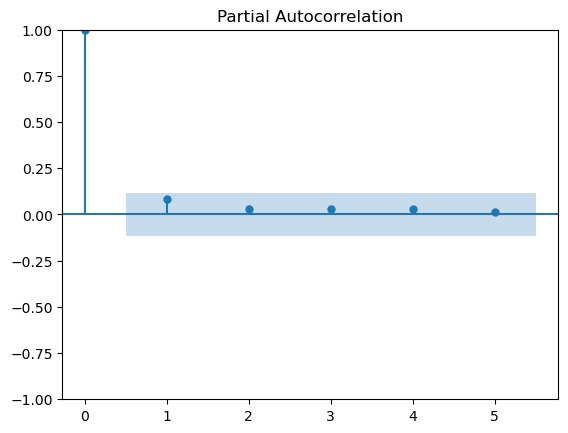

In [31]:
plot_acf(df['Returns'], lags=20)
plt.show()

plot_pacf(df['Returns'], lags=5)
plt.show()

In [32]:
ljung_box = acorr_ljungbox(df['Returns'], lags=[2,5,10,20], return_df=True)
print(ljung_box)

      lb_stat  lb_pvalue
2    2.353128   0.308336
5    3.285719   0.656029
10   7.071104   0.718716
20  15.388837   0.753743


# 10. Volatility Dynamics

### GARCH Test (Volatility Clustering)
Estimate GARCH(1,1).

In [33]:
model = arch_model(df['Returns'], vol='Garch', p=1, q=1)
garch_result = model.fit()

print(garch_result.summary())

Iteration:      1,   Func. Count:      6,   Neg. LLF: 1156.3222546098818
Iteration:      2,   Func. Count:     15,   Neg. LLF: 671.3627314620837
Iteration:      3,   Func. Count:     23,   Neg. LLF: -169.7648271862425
Iteration:      4,   Func. Count:     28,   Neg. LLF: -169.7934187894541
Iteration:      5,   Func. Count:     33,   Neg. LLF: -170.18103904361158
Iteration:      6,   Func. Count:     38,   Neg. LLF: -114.0233543464134
Iteration:      7,   Func. Count:     44,   Neg. LLF: -143.58328354547808
Iteration:      8,   Func. Count:     50,   Neg. LLF: 9722855417181.793
Iteration:      9,   Func. Count:     59,   Neg. LLF: 2797716.05380887
Iteration:     10,   Func. Count:     66,   Neg. LLF: 757.3312439795579
Iteration:     11,   Func. Count:     72,   Neg. LLF: 476.6970992421044
Iteration:     12,   Func. Count:     78,   Neg. LLF: -46.594725703402474
Iteration:     13,   Func. Count:     84,   Neg. LLF: 38.357480168664644
Iteration:     14,   Func. Count:     93,   Neg. LLF: 

c:\Users\vkpoa\anaconda3\Lib\site-packages\arch\univariate\base.py:694: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 0.01741. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 10 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  self._check_scale(resids)


Plot Conditional Volatility

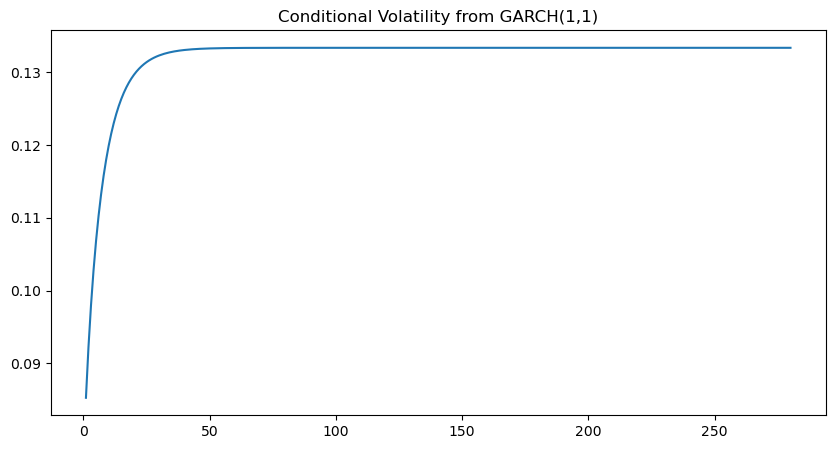

In [34]:
volatility = garch_result.conditional_volatility

plt.figure(figsize=(10,5))
plt.plot(volatility)
plt.title("Conditional Volatility from GARCH(1,1)")
plt.show()

# 10. ARIMA

In [35]:
model_full = ARIMA(df['Returns'], order=(1,0,1))
result_full = model_full.fit()

print(result_full.summary())

c:\Users\vkpoa\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: An unsupported index was provided and will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\vkpoa\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: An unsupported index was provided and will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\vkpoa\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: An unsupported index was provided and will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:                Returns   No. Observations:                  280
Model:                 ARIMA(1, 0, 1)   Log Likelihood                 171.530
Date:                Tue, 11 Aug 2026   AIC                           -335.061
Time:                        09:27:52   BIC                           -320.521
Sample:                             0   HQIC                          -329.229
                                - 280                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0095      0.024      0.392      0.695      -0.038       0.057
ar.L1          0.8487      0.398      2.134      0.033       0.069       1.628
ma.L1         -0.7880      0.439     -1.795      0.0

# 12. Forecasting Models

## Statistical Forecasting
ARIMA

In [36]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

split = int(len(df) * 0.8)

train = df['Returns'][:split]
test = df['Returns'][split:]

In [37]:
arima_model = ARIMA(train, order=(1,0,1))
arima_result = arima_model.fit()

# ARIMA predictions
arima_pred = arima_result.forecast(steps=len(test))

c:\Users\vkpoa\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: An unsupported index was provided and will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\vkpoa\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: An unsupported index was provided and will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\vkpoa\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: An unsupported index was provided and will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\vkpoa\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:836: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\Users\vkpoa\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:836: FutureWarning: No supported index is available. In the next versio

In [38]:
forecast = arima_result.forecast(steps=len(test))



c:\Users\vkpoa\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:836: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


In [39]:
print(forecast[forecast.isna()])

Series([], Name: predicted_mean, dtype: float64)


In [40]:
rmse = np.sqrt(mean_squared_error(test, forecast))
mae = mean_absolute_error(test, forecast)

print("RMSE:", rmse)
print("MAE:", mae)


RMSE: 0.07239180281132097
MAE: 0.04344382966377477


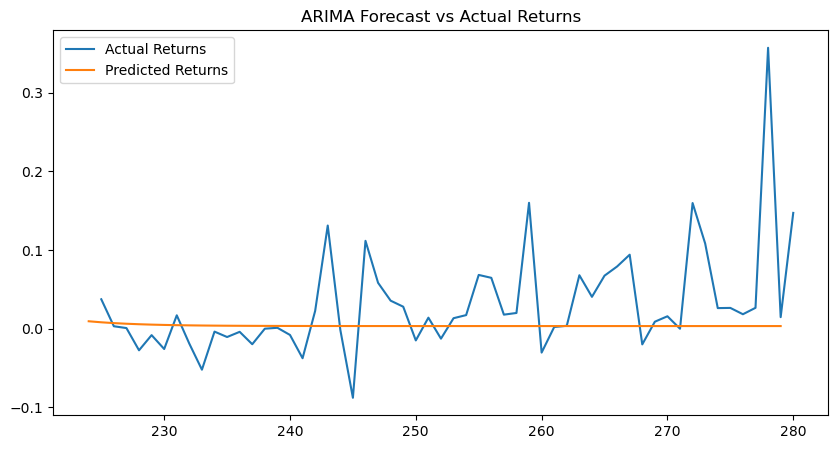

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
plt.plot(test, label='Actual Returns')
plt.plot(forecast, label='Predicted Returns')
plt.legend()
plt.title("ARIMA Forecast vs Actual Returns")
plt.show()

### Random Forest


In [42]:
# Random Forest needs predictor variables, so we create Lagged Returns
for i in range(1,6):
    df[f'lag_{i}'] = df['Returns'].shift(i)

df = df.dropna()

In [43]:
# Define features and Target
X = df[['lag_1','lag_2','lag_3','lag_4','lag_5']]
y = df['Returns']


In [44]:
# Train-Test split
train_size = int(len(df)*0.8)

X_train = X[:train_size]
X_test = X[train_size:]

y_train = y[:train_size]
y_test = y[train_size:]

In [45]:
# Training Random Forest Model
rf_model = RandomForestRegressor(
    n_estimators=500,
    max_depth=5,
    random_state=42
)

rf_model.fit(X_train, y_train)

RandomForestRegressor(max_depth=5, n_estimators=500, random_state=42)

In [46]:
# Generating predictions
predictions = rf_model.predict(X_test)

In [47]:
# Evaluating Model Performance
rmse = np.sqrt(mean_squared_error(y_test, predictions))
mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("RMSE:", rmse)
print("MAE:", mae)
print("R²:", r2)

RMSE: 0.09184125704067181
MAE: 0.05654285396928074
R²: -0.8388618612276182


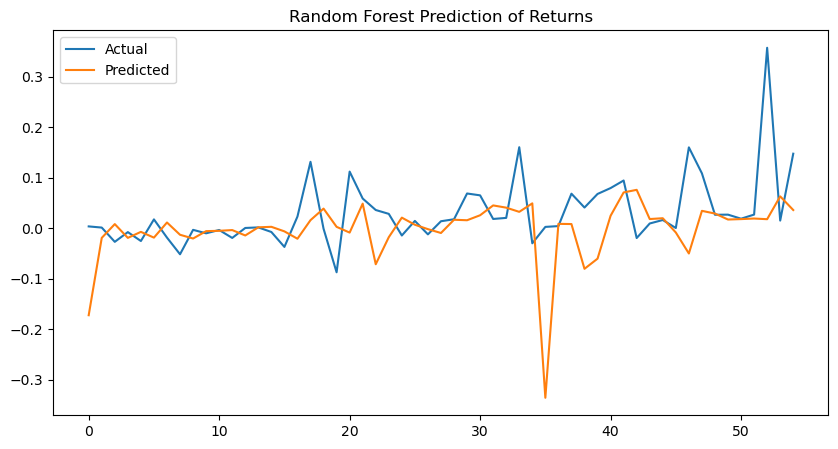

In [48]:
# Plotting Predictions vs Actual
plt.figure(figsize=(10,5))
plt.plot(y_test.values, label="Actual")
plt.plot(predictions, label="Predicted")
plt.legend()
plt.title("Random Forest Prediction of Returns")
plt.show()

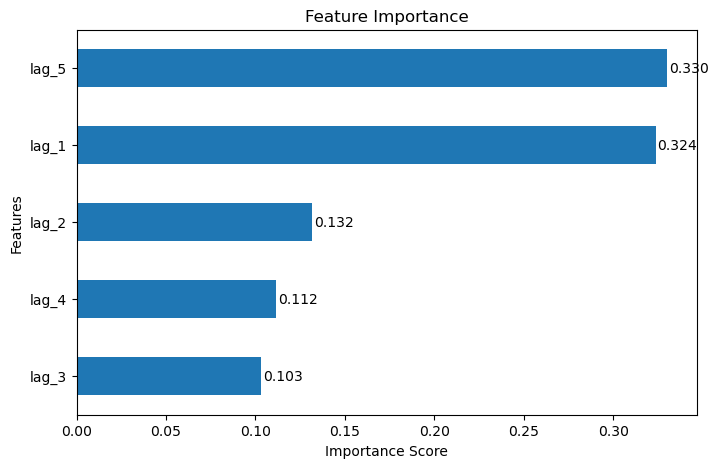

In [49]:
# Feature importance
importance = rf_model.feature_importances_
features = pd.Series(importance, index=X.columns)

# Sort values
features_sorted = features.sort_values()

# Plot
plt.figure(figsize=(8,5))
ax = features_sorted.plot(kind='barh')

# Add value labels
for i, v in enumerate(features_sorted):
    ax.text(v + 0.001, i, f"{v:.3f}", va='center')

plt.title("Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()

In [50]:
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler

# Scale data (important for SVR)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

svr = SVR(kernel='rbf', C=1.0, epsilon=0.01)
svr.fit(X_train_scaled, y_train)

svr_pred = svr.predict(X_test_scaled)

svr_rmse = np.sqrt(mean_squared_error(y_test, svr_pred))
svr_r2 = r2_score(y_test, svr_pred)

print("SVR RMSE:", svr_rmse)
print("SVR MAE:", mae)
print("SVR R²:", svr_r2)

SVR RMSE: 0.0732433336264322
SVR MAE: 0.05654285396928074
SVR R²: -0.16952543744685844


### Building ANN

In [51]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import Input
# Build ANN model
ann_model = Sequential()

ann_model.add(Dense(32,
                    activation='relu',
                    input_shape=(X_train_scaled.shape[1],)))

ann_model.add(Dropout(0.2))

ann_model.add(Dense(16, activation='relu'))

ann_model.add(Dropout(0.2))

ann_model.add(Dense(1))

ann_model.compile(
    optimizer='adam',
    loss='mse'
)

ann_model.summary()

c:\Users\vkpoa\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 737 (2.88 KB)

 Trainable params: 737 (2.88 KB)

 Non-trainable params: 0 (0.00 B)

In [52]:
# Training the Model

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=20,
    restore_best_weights=True
)

history = ann_model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=200,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - loss: 0.0907 - val_loss: 0.0059
Epoch 2/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.1788 - val_loss: 0.0046
Epoch 3/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0580 - val_loss: 0.0042
Epoch 4/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0672 - val_loss: 0.0036
Epoch 5/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0642 - val_loss: 0.0031
Epoch 6/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0335 - val_loss: 0.0027
Epoch 7/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0716 - val_loss: 0.0026
Epoch 8/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0345 - val_loss: 0.0025
Epoch 9/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0372 - val_loss: 0.0024
Epoch 10/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0340 - val_loss: 0.0024
Epoch 11/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0366 - val_loss: 0.0024
Epoch 12/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step

In [53]:
# Prediction


pred = ann_model.predict(X_test_scaled)

pred = pred.flatten()

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step


In [54]:
# Model Evaluation

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score, mean_absolute_percentage_error
)

rmse = np.sqrt(mean_squared_error(y_test, pred))
mae = mean_absolute_error(y_test, pred)
r2 = r2_score(y_test, pred)
mape = mean_absolute_percentage_error(y_test, pred)


print("ANN RMSE:", rmse)
print("ANN MAE :", mae)
print("MAPE:", mape)
print("ANN R²  :", r2)

ANN RMSE: 0.07801638170700957
ANN MAE : 0.05001838518078876
MAPE: 3271805422801.742
ANN R²  : -0.32692102557131264


In [55]:
# Directional Accuracy

direction = np.mean(
    np.sign(pred) ==
    np.sign(y_test)
)

print("Directional Accuracy:", direction)

Directional Accuracy: 0.5272727272727272


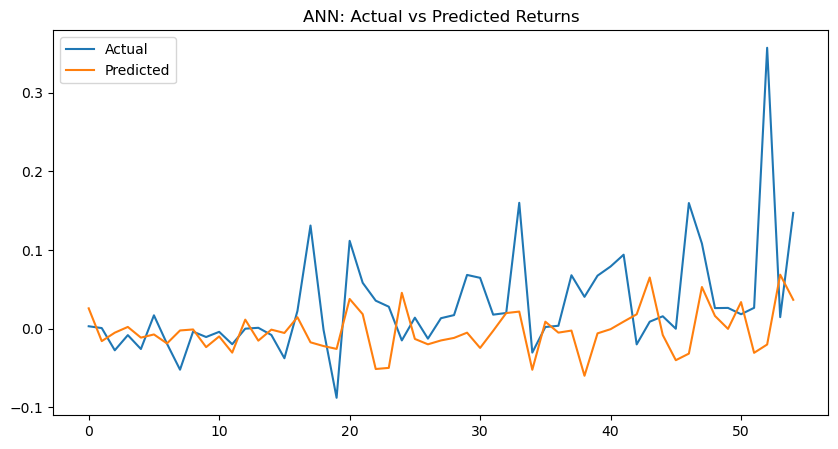

In [56]:
# Actual vs Predicted Plot


import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(y_test.values, label='Actual')
plt.plot(pred, label='Predicted')

plt.legend()

plt.title("ANN: Actual vs Predicted Returns")

plt.show()

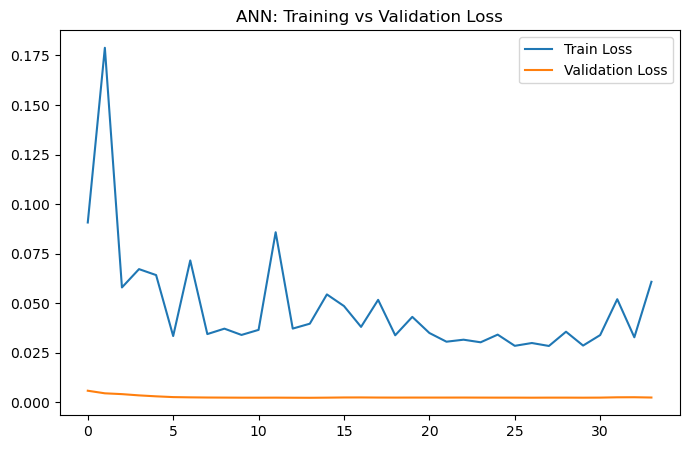

In [57]:
# Training Loss Curve

plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.legend()

plt.title("ANN: Training vs Validation Loss")

plt.show()

In [58]:
# Saving Metrics

ann_rmse = rmse
ann_mae = mae
ann_r2 = r2
ann_da = direction

In [59]:
from xgboost import XGBRegressor

xgb = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    random_state=42
)

xgb.fit(X_train, y_train)

xgb_pred = xgb.predict(X_test)

xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_pred))
xgb_r2 = r2_score(y_test, xgb_pred)

print("XGBoost RMSE:", xgb_rmse)
print("XGBoost MAE:", mae)
print("XGBoost R²:", xgb_r2)

XGBoost RMSE: 0.09930794428630262
XGBoost MAE: 0.05001838518078876
XGBoost R²: -1.15001480570717


XGBoost RMSE: 0.08880791012517608
XGBoost MAE: 0.06020790070567127
XGBoost R²: -0.6931818339083682


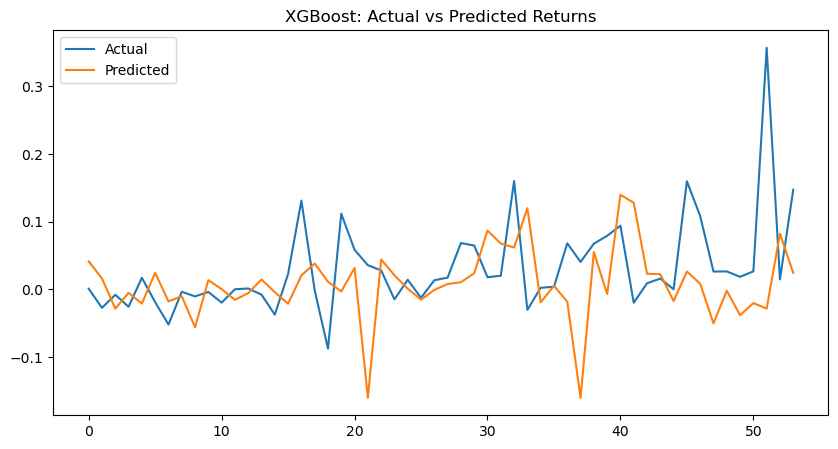

In [89]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import numpy as np
import matplotlib.pyplot as plt

# XGBoost Model
xgb = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    random_state=42
)

# Train
xgb.fit(X_train, y_train)

# Predict
xgb_pred = xgb.predict(X_test)

# Evaluation
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_pred))
xgb_mae = mean_absolute_error(y_test, xgb_pred)
xgb_r2 = r2_score(y_test, xgb_pred)

print("XGBoost RMSE:", xgb_rmse)
print("XGBoost MAE:", xgb_mae)
print("XGBoost R²:", xgb_r2)

# Actual vs Predicted Plot
plt.figure(figsize=(10, 5))

plt.plot(y_test.values, label='Actual')
plt.plot(xgb_pred, label='Predicted')

plt.legend()

plt.title("XGBoost: Actual vs Predicted Returns")
plt.show()

## LTSM

In [60]:
# Using past returns to predict current returns
n_lags = 5

for i in range(1, n_lags + 1):
    df[f'lag_{i}'] = df['Returns'].shift(i)

df = df.dropna()

In [61]:
# Define Features and Target
X = df[[f'lag_{i}' for i in range(1, n_lags + 1)]]
y = df['Returns']

In [62]:
# Train-Test Split
split = int(len(df) * 0.8)

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

In [63]:
# Scaling
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1,1))
y_test_scaled = scaler_y.transform(y_test.values.reshape(-1,1))

In [64]:
# Reshaping into [samples,timesamps,features]. LSTM expects that
X_train_lstm = X_train_scaled.reshape((X_train_scaled.shape[0], n_lags, 1))
X_test_lstm = X_test_scaled.reshape((X_test_scaled.shape[0], n_lags, 1))

In [65]:
# Building the LSTM Model
model = Sequential()

# LSTM layer
model.add(LSTM(64, return_sequences=False, input_shape=(n_lags,1)))

# Dropout to prevent overfitting
model.add(Dropout(0.2))

# Dense output
model.add(Dense(1))

model.compile(optimizer='adam', loss='mse')

c:\Users\vkpoa\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [66]:
# Training the Model
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train_lstm, y_train_scaled,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50


6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 102ms/step - loss: 1.0568 - val_loss: 0.7742
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.6649 - val_loss: 0.4467
Epoch 3/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.3578 - val_loss: 0.1971
Epoch 4/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.1417 - val_loss: 0.0368
Epoch 5/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0265 - val_loss: 0.0040
Epoch 6/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0295 - val_loss: 0.0225
Epoch 7/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0332 - val_loss: 0.0062
Epoch 8/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0160 - val_loss: 9.3475e-04
Epoch 9/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0154 - val_loss: 0.0039
Epoch 10/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0161 - val_loss: 0.0028
Epoch 11/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.0138 - val_loss: 8.9371e-04
Epoch 12/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.0126 - val_loss: 5.9533e-04

In [67]:
# Predictions
pred_scaled = model.predict(X_test_lstm)

# Inverse scaling
pred = scaler_y.inverse_transform(pred_scaled)
y_actual = scaler_y.inverse_transform(y_test_scaled)

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 269ms/step


In [68]:
# Model Evaluation
rmse = np.sqrt(mean_squared_error(y_actual, pred))
mae = mean_absolute_error(y_actual, pred)
r2 = r2_score(y_actual, pred)

print("LSTM RMSE:", rmse)
print("LSTM MAE:", mae)
print("LSTM R²:", r2)

LSTM RMSE: 0.0693855593311813
LSTM MAE: 0.04345207795020108
LSTM R²: -0.033566649154805894


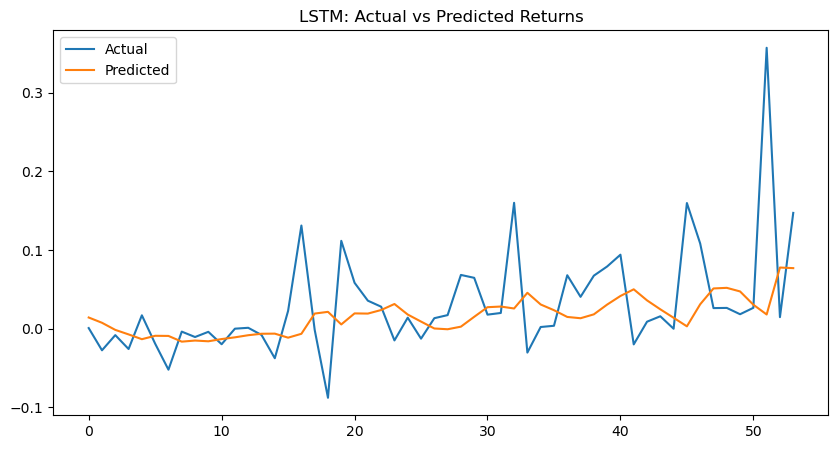

In [69]:
# Plot Results
plt.figure(figsize=(10,5))
plt.plot(y_actual, label='Actual')
plt.plot(pred, label='Predicted')
plt.legend()
plt.title("LSTM: Actual vs Predicted Returns")
plt.show()

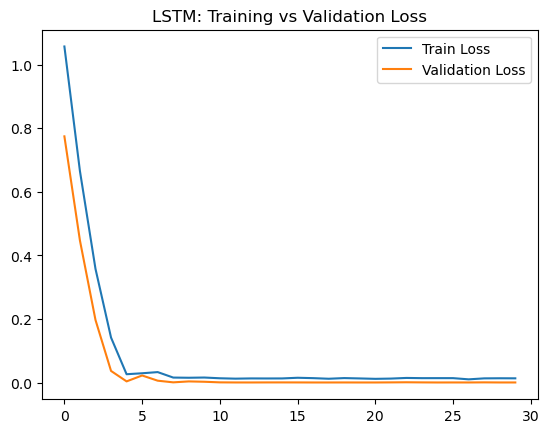

In [70]:
# Training Loss Curve
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title("LSTM: Training vs Validation Loss")
plt.show()

In [71]:
# Directional Accuracy
direction_actual = np.sign(y_actual)
direction_pred = np.sign(pred)

accuracy = np.mean(direction_actual == direction_pred)

print("Directional Accuracy:", accuracy)

Directional Accuracy: 0.7407407407407407


### LSTM +  Attention Model


In [72]:
# Custom Attention Layer

class AttentionLayer(tf.keras.layers.Layer):
    def __init__(self):
        super(AttentionLayer, self).__init__()

    def build(self, input_shape):
        self.W = self.add_weight(name="att_weight",
                                 shape=(input_shape[-1], 1),
                                 initializer="normal")
        self.b = self.add_weight(name="att_bias",
                                 shape=(input_shape[1], 1),
                                 initializer="zeros")

    def call(self, x):
        # Score
        e = tf.keras.backend.tanh(tf.keras.backend.dot(x, self.W) + self.b)
        
        # Attention weights
        a = tf.keras.backend.softmax(e, axis=1)
        
        # Context vector
        context = x * a
        context = tf.keras.backend.sum(context, axis=1)
        
        return context, a

In [73]:
# Buld LSTM + Attention Model
inputs = Input(shape=(n_lags,1))

lstm_out = LSTM(64, return_sequences=True)(inputs)
lstm_out = Dropout(0.2)(lstm_out)

context_vector, attention_weights = AttentionLayer()(lstm_out)

output = Dense(1)(context_vector)

model = Model(inputs=inputs, outputs=output)

model.compile(optimizer='adam', loss='mse')

model.summary()

Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 5, 1)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 5, 64)          │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 5, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ attention_layer                 │ [(None, 64), (None, 5, │            69 │
│ (AttentionLayer)                │ 1)]                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,030 (66.52 KB)

 Trainable params: 17,030 (66.52 KB)

 Non-trainable params: 0 (0.00 B)

In [74]:
# Training Model
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train_lstm, y_train_scaled,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 111ms/step - loss: 0.9143 - val_loss: 0.7587
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.6899 - val_loss: 0.5548
Epoch 3/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.4948 - val_loss: 0.3673
Epoch 4/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.3076 - val_loss: 0.1950
Epoch 5/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.1444 - val_loss: 0.0551
Epoch 6/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0313 - val_loss: 7.3000e-04
Epoch 7/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.0189 - val_loss: 0.0234
Epoch 8/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0270 - val_loss: 0.0066
Epoch 9/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0111 - val_loss: 9.1141e-04
Epoch 10/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0085 - val_loss: 0.0035
Epoch 11/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.0117 - val_loss: 0.0021


In [75]:
# Prediction

pred_scaled = model.predict(X_test_lstm)

pred = scaler_y.inverse_transform(pred_scaled)
y_actual = scaler_y.inverse_transform(y_test_scaled)

1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 402ms/stepWARNING:tensorflow:6 out of the last 6 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x0000029CC5BB8720> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 388ms/step


In [76]:
# Evaluation of Metrics
rmse = np.sqrt(mean_squared_error(y_actual, pred))
mae = mean_absolute_error(y_actual, pred)
r2 = r2_score(y_actual, pred)

print("RMSE:", rmse)
print("MAE:", mae)
print("R²:", r2)

RMSE: 0.07140780097079977
MAE: 0.051205481302448196
R²: -0.0946911777779631


In [77]:
# Directional Accuracy

direction_actual = np.sign(y_actual)
direction_pred = np.sign(pred)

accuracy = np.mean(direction_actual == direction_pred)

print("Directional Accuracy:", accuracy)

Directional Accuracy: 0.6666666666666666


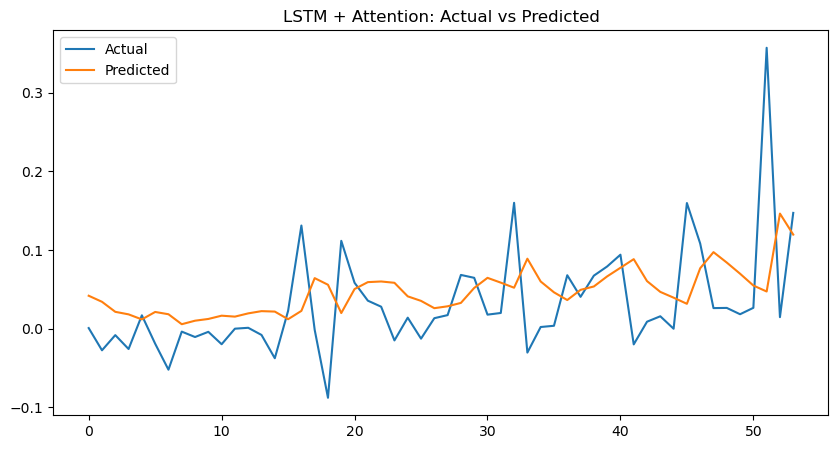

In [78]:
# Plotting Predictions

plt.figure(figsize=(10,5))
plt.plot(y_actual, label='Actual')
plt.plot(pred, label='Predicted')
plt.legend()
plt.title("LSTM + Attention: Actual vs Predicted")
plt.show()

### Extract and Visualize Attention Weights (VERY IMPORTANT)

Create a separate model to output attention weights:

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 333ms/step


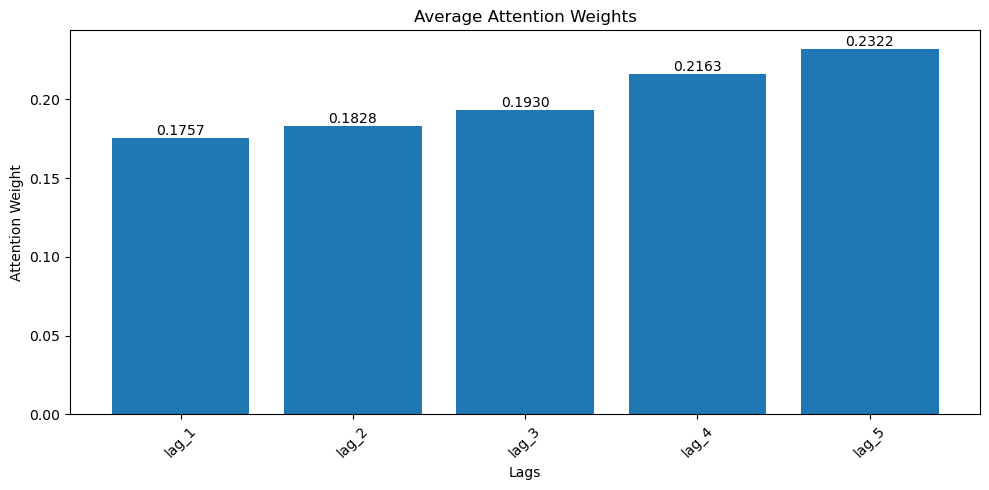

Attention Weights: {'lag_1': 0.17574507, 'lag_2': 0.18277693, 'lag_3': 0.19300127, 'lag_4': 0.21628867, 'lag_5': 0.23218803}


In [79]:
attention_model = Model(inputs=inputs, outputs=attention_weights)

att_weights = attention_model.predict(X_test_lstm)

# Average attention across samples
avg_attention = np.mean(att_weights, axis=0).flatten()

lags = [f'lag_{i}' for i in range(1, n_lags+1)]

plt.figure(figsize=(10,5))
bars = plt.bar(lags, avg_attention)

plt.title("Average Attention Weights")
plt.xlabel("Lags")
plt.ylabel("Attention Weight")

# Add values on top of bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f'{height:.4f}',   # format to 4 decimal places
        ha='center',
        va='bottom'
    )

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Attention Weights:", dict(zip(lags, avg_attention)))

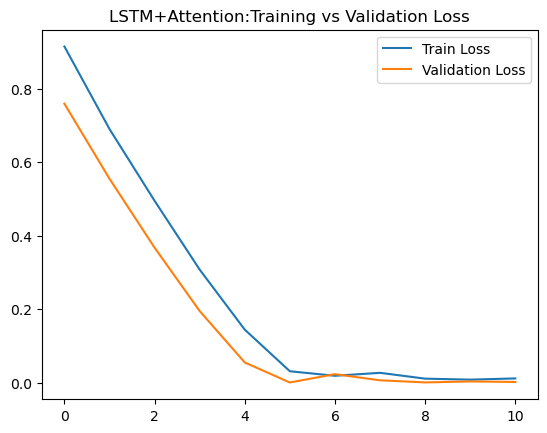

In [80]:
#  Training Loss

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title("LSTM+Attention:Training vs Validation Loss")
plt.show()

### Bidirectional LSTM

In [81]:
from tensorflow.keras.layers import Bidirectional

# Building the Model

model = Sequential()

model.add(Bidirectional(LSTM(64, return_sequences=False), input_shape=(n_lags,1)))
model.add(Dropout(0.2))
model.add(Dense(1))

model.compile(optimizer='adam', loss='mse')

model.summary()

c:\Users\vkpoa\anaconda3\Lib\site-packages\keras\src\layers\rnn\bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 128)            │        33,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,921 (132.50 KB)

 Trainable params: 33,921 (132.50 KB)

 Non-trainable params: 0 (0.00 B)

In [82]:
# Training the model

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train_lstm, y_train_scaled,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 140ms/step - loss: 0.7257 - val_loss: 0.4247
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.3066 - val_loss: 0.1157
Epoch 3/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0641 - val_loss: 8.4021e-04
Epoch 4/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0189 - val_loss: 0.0371
Epoch 5/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0436 - val_loss: 0.0206
Epoch 6/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0215 - val_loss: 6.1209e-04
Epoch 7/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.0126 - val_loss: 0.0053
Epoch 8/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0154 - val_loss: 0.0050
Epoch 9/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0139 - val_loss: 0.0011
Epoch 10/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0098 - val_loss: 7.2126e-04
Epoch 11/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0114 - val_loss: 9.7810e-04


In [83]:
# Prediction

pred_scaled = model.predict(X_test_lstm)

# Inverse scaling
pred = scaler_y.inverse_transform(pred_scaled)
y_actual = scaler_y.inverse_transform(y_test_scaled)

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 781ms/step


In [84]:
# Evaluation

rmse = np.sqrt(mean_squared_error(y_actual, pred))
mae = mean_absolute_error(y_actual, pred)
r2 = r2_score(y_actual, pred)

print("BiLSTM RMSE:", rmse)
print("BiLSTM MAE:", mae)
print("BiLSTM R²:", r2)

BiLSTM RMSE: 0.0670690378657883
BiLSTM MAE: 0.04556406715176643
BiLSTM R²: 0.03429506110903424


In [85]:
# Directional Accuracy

direction_actual = np.sign(y_actual)
direction_pred = np.sign(pred)

accuracy = np.mean(direction_actual == direction_pred)

print("Directional Accuracy:", accuracy)

Directional Accuracy: 0.7222222222222222


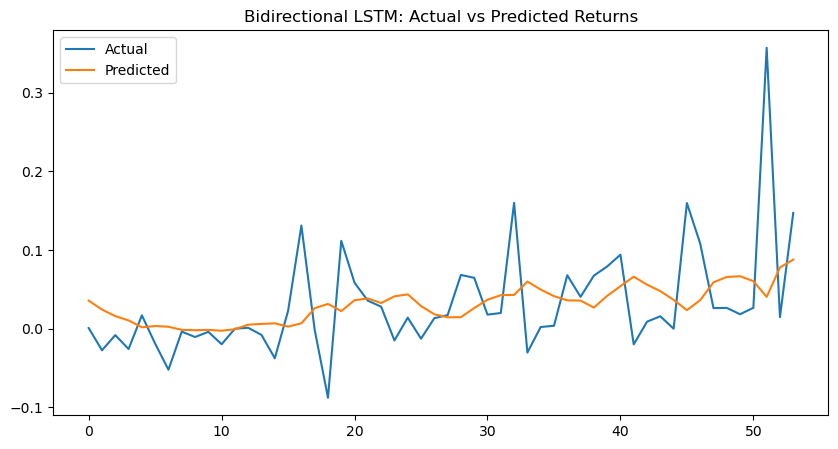

In [86]:
# Plot Predictions

plt.figure(figsize=(10,5))
plt.plot(y_actual, label='Actual')
plt.plot(pred, label='Predicted')
plt.legend()
plt.title("Bidirectional LSTM: Actual vs Predicted Returns")
plt.show()

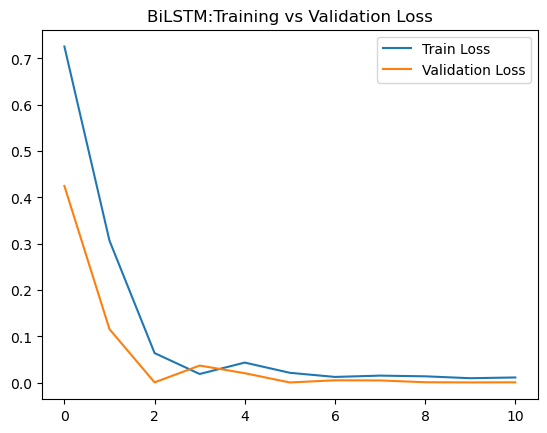

In [87]:
# Training Loss Curve

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title("BiLSTM:Training vs Validation Loss")
plt.show()

In [88]:
# Compare with Standard LSTM

results = pd.DataFrame({
    'Model': ['LSTM', 'BiLSTM'],
    'RMSE': [lstm_rmse, rmse],
    'R2': [lstm_r2, r2]
})

print(results)

NameError: name 'lstm_rmse' is not defined

### Hybrid ARIMA-LSTM

In [ ]:
# Extract Residuals (Training Phase)
residuals = arima_result.resid

# Create Lagged Residuals

n_lags = 5

res_df = pd.DataFrame(residuals)
res_df.columns = ['residual']

for i in range(1, n_lags+1):
    res_df[f'lag_{i}'] = res_df['residual'].shift(i)

res_df = res_df.dropna()

X_res = res_df[[f'lag_{i}' for i in range(1, n_lags+1)]]
y_res = res_df['residual']

In [ ]:
# Scale Residual Data

scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_res_scaled = scaler_X.fit_transform(X_res)
y_res_scaled = scaler_y.fit_transform(y_res.values.reshape(-1,1))

In [ ]:
# Reshape for LSTM

X_res_lstm = X_res_scaled.reshape((X_res_scaled.shape[0], n_lags, 1))

### Prepare Test Residual Inputs
We need residual lags aligned with test period:

In [ ]:
# Combine full residuals (train + test ARIMA errors)
full_residuals = df['Returns'] - arima_result.predict(start=0, end=len(df)-1)

res_test_df = pd.DataFrame(full_residuals)
res_test_df.columns = ['residual']

for i in range(1, n_lags+1):
    res_test_df[f'lag_{i}'] = res_test_df['residual'].shift(i)

res_test_df = res_test_df.dropna()

# Align with test index
common_index = res_test_df.index.intersection(test.index)

res_test_df = res_test_df.loc[common_index]
test_aligned = test.loc[common_index]

X_test_res = res_test_df[[f'lag_{i}' for i in range(1, n_lags+1)]]

c:\Users\vkpoa\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\Users\vkpoa\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


In [ ]:
# Scale and Reshape Test Data
X_test_res_scaled = scaler_X.transform(X_test_res)
X_test_res_lstm = X_test_res_scaled.reshape((X_test_res_scaled.shape[0], n_lags, 1))

In [ ]:
# Predict Residual Data
res_pred_scaled = model.predict(X_test_res_lstm)
res_pred = scaler_y.inverse_transform(res_pred_scaled)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


In [ ]:
# Combine ARIMA + LSTM Predictions

# Align ARIMA predictions
arima_pred = arima_pred[:len(res_pred)]

hybrid_pred = arima_pred.values.reshape(-1,1) + res_pred

In [ ]:
# Evaluate Hybrid Model

y_actual = test.values[:len(hybrid_pred)].reshape(-1,1)

rmse = np.sqrt(mean_squared_error(y_actual, hybrid_pred))
mae = mean_absolute_error(y_actual, hybrid_pred)
r2 = r2_score(y_actual, hybrid_pred)

print("Hybrid RMSE:", rmse)
print("Hybrid MAE:", mae)
print("Hybrid R²:", r2)

Hybrid RMSE: 0.04653273385722743
Hybrid MAE: 0.031171355660397516
Hybrid R²: 0.06322467474068738


In [ ]:
# Directional Accuracy

direction_actual = np.sign(y_actual)
direction_pred = np.sign(hybrid_pred)

accuracy = np.mean(direction_actual == direction_pred)

print("Directional Accuracy:", accuracy)

Directional Accuracy: 0.6571428571428571


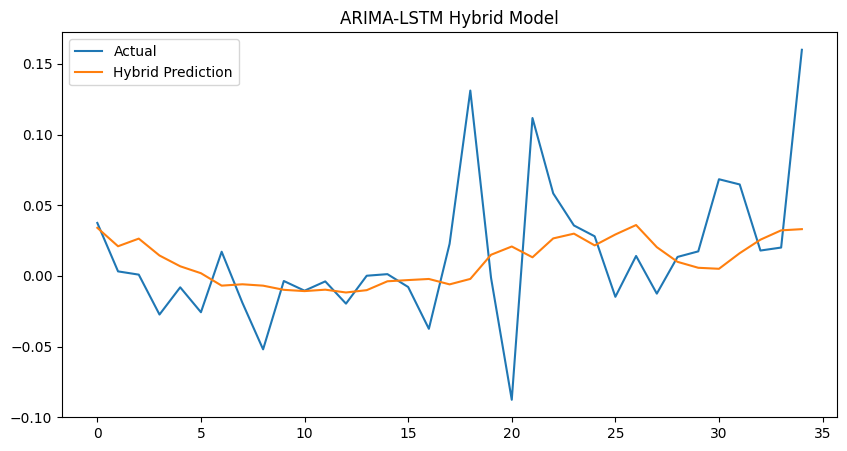

In [ ]:
# Plotting Results

plt.figure(figsize=(10,5))
plt.plot(y_actual, label='Actual')
plt.plot(hybrid_pred, label='Hybrid Prediction')
plt.legend()
plt.title("ARIMA-LSTM Hybrid Model")
plt.show()